# 11 · Liga de oponentes, arena y matriz de counters
**Entorno:** MiniCartas (3 arquetipos de mazo) · **Tiempo de ejecución:** ≤ 6 min en CPU · **Criterio de la lección:** determinismo de la arena, muestreo balanceado por arquetipo,
Elo plano en piedra-papel-tijera y ≥ 3 pares de la liga real con diferencia estadísticamente distinta de 50 % (15 pares × 1000 partidas).

## 1. La idea en una frase
Para saber qué modelo subir no basta ganarle a un aleatorio: hace falta una **liga** de oponentes variados, balanceada por arquetipo, y una **arena** con el mismo número de partidas por par que produzca la matriz de quién le gana a quién.

**En el sistema de Luca:** liga de oponentes balanceada por arquetipo y una arena local con n fijo por par para elegir qué subir.
**En un problema de negocio:** varias reglas de despacho (o estrategias de competidores) evaluadas cruzadas: una regla puede ser buena en promedio y mala contra un caso específico.

## 2. La intuición y la fórmula
- **Muestreo balanceado:** primero un arquetipo uniforme y luego una entrada uniforme dentro de él. Si un arquetipo tiene 5 entradas y otro 1, el muestreo uniforme sobre entradas mostraría 5 veces más el primero.
- **Matriz de counters** $W_{ij}$: tasa de victoria de $i$ contra $j$ (con IC de Wilson por celda). Puede tener **ciclos** (piedra-papel-tijera): nadie domina.
- **Elo** resume $W$ en un solo número por agente, suponiendo un orden lineal; **maximin** elige al agente con mejor *peor caso*: $\arg\max_i \min_j W_{ij}$.
  Los dos responden preguntas distintas y pueden discrepar.

In [1]:
import os
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from rlf.core import EVAL_SEED_BASE, VecEnv, seed_everything
from rlf.eval.stats import proportion_ci
from rlf.eval.arena import League, counter_matrix, elo_ratings, select_maximin
from rlf.envs.cartas import CartasConfig, CartasEnv
from rlf.envs.wrappers import VsOpponent
from rlf.agents.baselines import HeuristicCartas
from rlf.agents.policy import ActorCriticPolicy
from rlf.agents.ppo import PPO, PPOConfig
from rlf.nets.pointer import PointerActorCritic
TRAIN_SEED = int(os.environ.get("RLF_TRAIN_SEED", "0"))
seed_everything(TRAIN_SEED)
DECKS = ["aggro", "tank", "dragon"]

## 3. El núcleo: muestreo balanceado y maximin
Inline, y una celda comprueba que dan lo mismo que `League.sample` y `select_maximin` de `rlf`.

In [2]:
def sample_balanced(entries, rng):
    """entries: {nombre: arquetipo}. Primero un arquetipo uniforme; luego una entrada uniforme de ese arquetipo."""
    archetypes = sorted(set(entries.values()))
    a = archetypes[int(rng.integers(len(archetypes)))]
    names = [n for n, x in entries.items() if x == a]
    return names[int(rng.integers(len(names)))]

def maximin_inline(W):
    """Índice del agente cuyo PEOR enfrentamiento es el mejor: argmax_i min_j W[i, j] (la diagonal es NaN y se ignora)."""
    return int(np.argmax(np.nanmin(W, axis=1)))

entries_541 = {**{f"a{i}": "A" for i in range(5)}, "b0": "B", "c0": "C"}
league_541 = League()
for n_, a_ in entries_541.items():
    league_541.add(n_, None, a_)
r1, r2 = np.random.default_rng(TRAIN_SEED), np.random.default_rng(TRAIN_SEED)
assert all(sample_balanced(entries_541, r1) == league_541.sample(r2) for _ in range(2000))
W_test = np.array([[np.nan, 0.9, 0.2], [0.1, np.nan, 0.6], [0.8, 0.4, np.nan]])
assert maximin_inline(W_test) == select_maximin(W_test) == 2
print("muestreo balanceado y maximin inline == rlf")

muestreo balanceado y maximin inline == rlf


## 4. Entrenar la liga y graficar
La liga tiene 6 entradas: `HeuristicCartas` y un **especialista PPO** (pointer, 150 000 pasos ≈ 50 s) por cada uno de los tres mazos. Cada especialista juega con su mazo y se entrena contra la mezcla de las
heurísticas (mazo del rival al azar entre los tres). Luego la arena juega los 15 pares con n = 1000 partidas (500 por asiento; al intercambiar asientos se intercambian los mazos).

especialista aggro: entrenado (49 s acumulados)


especialista tank: entrenado (94 s acumulados)


especialista dragon: entrenado (141 s acumulados)


arena: 15 pares × 1000 partidas en 45 s


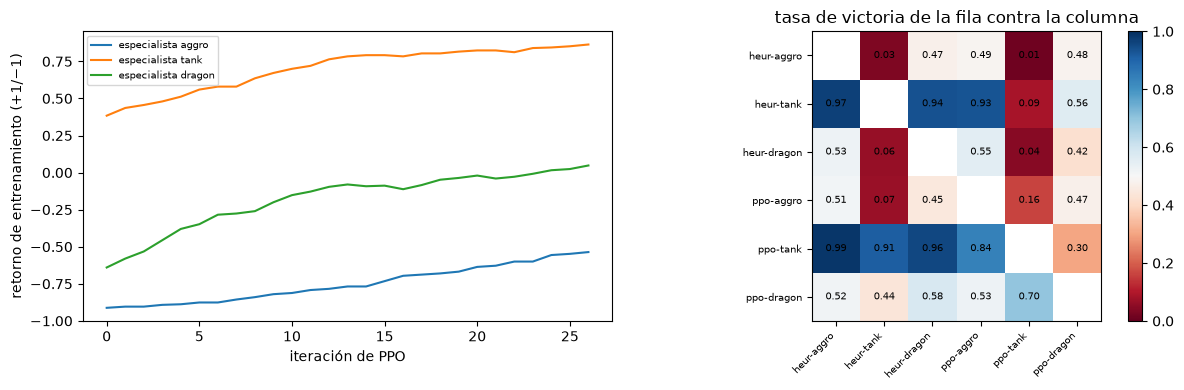

In [3]:
def specialist_env(deck):
    def configure(env, seat):                       # el mazo del especialista sigue a su asiento
        env.core.cfg = CartasConfig(deck, "random") if seat == 0 else CartasConfig("random", deck)
    return lambda: VsOpponent(lambda: CartasEnv(), HeuristicCartas(), configure=configure)

entrants, deck_of, histories = {}, {}, {}
for d in DECKS:
    entrants[f"heur-{d}"], deck_of[f"heur-{d}"] = HeuristicCartas(), d
t0 = time.time()
for d in DECKS:
    torch.manual_seed(TRAIN_SEED)
    net = PointerActorCritic(CartasEnv().spec)
    ppo = PPO(net, PPOConfig(gamma=1.0, lam=0.95, lr=1e-3, epochs=6, minibatches=8), seed=TRAIN_SEED)
    ppo.train(VecEnv(specialist_env(d), 64, seed=TRAIN_SEED), 150_000)
    entrants[f"ppo-{d}"], deck_of[f"ppo-{d}"], histories[d] = ActorCriticPolicy(net, greedy=True), d, ppo.history
    print(f"especialista {d}: entrenado ({time.time() - t0:.0f} s acumulados)")

def pair_env(a, b, a_at_seat1):
    da, db = deck_of[a], deck_of[b]
    return (lambda: CartasEnv(CartasConfig(db, da))) if a_at_seat1 else (lambda: CartasEnv(CartasConfig(da, db)))

t0 = time.time()
CM = counter_matrix(None, entrants, 1000, make_env_pair=pair_env)
print(f"arena: 15 pares × 1000 partidas en {time.time() - t0:.0f} s")
names = CM.names
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for d in DECKS:
    ax[0].plot(np.convolve([h["mean_return"] for h in histories[d]], np.ones(10) / 10, mode="valid"), label=f"especialista {d}")
ax[0].set_xlabel("iteración de PPO"); ax[0].set_ylabel("retorno de entrenamiento (+1/−1)"); ax[0].legend(fontsize=7)
im = ax[1].imshow(CM.rate, vmin=0, vmax=1, cmap="RdBu"); ax[1].set_xticks(range(6)); ax[1].set_yticks(range(6))
ax[1].set_xticklabels(names, rotation=45, ha="right", fontsize=7); ax[1].set_yticklabels(names, fontsize=7)
for i in range(6):
    for j in range(6):
        if i != j:
            ax[1].text(j, i, f"{CM.rate[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax[1].set_title("tasa de victoria de la fila contra la columna"); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

## 5. Experimentos "predice antes de correr"

### Experimento 1 · ¿El ranking por Elo coincide con el ranking por maximin?
**Predice:** ¿quién sale primero según cada criterio?

In [4]:
elo = elo_ratings(CM.rate, 1000)
by_elo = [names[i] for i in np.argsort(-elo)]
worst = np.nanmin(CM.rate, axis=1)
by_maximin = [names[i] for i in np.argsort(-worst)]
print("Elo    :", [(n, round(float(elo[names.index(n)]))) for n in by_elo])
print("maximin:", [(n, round(float(worst[names.index(n)]), 3)) for n in by_maximin])
assert by_maximin[0] == names[select_maximin(CM.rate)]
rank_e = np.argsort(np.argsort(-elo)); rank_m = np.argsort(np.argsort(-worst))
spearman = float(np.corrcoef(rank_e, rank_m)[0, 1])
print(f"¿mismo primer lugar? {by_elo[0] == by_maximin[0]};  correlación de rangos (Spearman) = {spearman:.2f}")
assert spearman >= 0.6                                         # los rankings se parecen en general

Elo    : [('ppo-tank', 1359), ('heur-tank', 1276), ('ppo-dragon', 1175), ('ppo-aggro', 1025), ('heur-dragon', 1016), ('heur-aggro', 1000)]
maximin: [('ppo-dragon', 0.44), ('ppo-tank', 0.303), ('heur-tank', 0.087), ('ppo-aggro', 0.068), ('heur-dragon', 0.043), ('heur-aggro', 0.013)]
¿mismo primer lugar? False;  correlación de rangos (Spearman) = 0.83


<details><summary>Respuesta esperada</summary>

Los rankings completos se **parecen mucho** (correlación de rangos ≈ 0,83), pero el primer lugar **puede diferir**. Con la semilla 0 no coinciden: Elo pone primero a `ppo-tank` (el que más le gana a casi todos),
pero su peor caso es perder contra `ppo-dragon` (≈ 0,30); maximin elige entonces a `ppo-dragon` (peor caso ≈ 0,44). Con la semilla 1, en cambio, `ppo-tank` domina con tanta claridad que ambos criterios lo eligen.
Elo promedia el desempeño contra todos; maximin protege del rival que más complica: cuando hay un talón de Aquiles conviene mirar ambos.
</details>

### Experimento 2 · ¿La matriz tiene ciclos?
**Predice:** ¿hay tríos $A>B>C>A$ donde cada relación es estadísticamente significativa?

In [5]:
E = len(names)
beats = np.array([[bool(CM.lo[i, j] > 0.5) if i != j else False for j in range(E)] for i in range(E)])
cycles = [(names[i], names[j], names[k]) for i in range(E) for j in range(E) for k in range(E)
          if len({i, j, k}) == 3 and i < j and i < k and beats[i, j] and beats[j, k] and beats[k, i]]
print("ciclos significativos:", cycles if cycles else "ninguno")
print("pares significativos:", int(CM.excludes_half().sum() // 2), "de 15")
assert CM.excludes_half().sum() // 2 >= 3
# el mismo test sobre una matriz piedra-papel-tijera sintética, para ver cómo se ve un ciclo
rps = np.array([[np.nan, 0.75, 0.25], [0.25, np.nan, 0.75], [0.75, 0.25, np.nan]])
rps_beats = np.nan_to_num(rps) > 0.5
assert rps_beats[0, 1] and rps_beats[1, 2] and rps_beats[2, 0]

ciclos significativos: [('heur-tank', 'ppo-dragon', 'ppo-tank')]
pares significativos: 11 de 15


<details><summary>Respuesta esperada</summary>

**Depende de la corrida.** Con la semilla 0 hay un ciclo significativo: `heur-tank` le gana a `ppo-dragon` (≈ 0,56), `ppo-dragon` le gana a `ppo-tank` (≈ 0,70) y `ppo-tank` le gana a `heur-tank` (≈ 0,91): nadie domina a todos.
Con otras semillas de entrenamiento puede no aparecer (el especialista de `tank` puede salir dominante). Fuera de eso, las relaciones forman un orden casi lineal y la mayoría de los pares es significativa. Los mazos no se calibraron
como piedra-papel-tijera (decisión de diseño); la celda incluye una matriz sintética de piedra-papel-tijera para ver un ciclo "puro", donde Elo da ratings idénticos.
</details>

### Experimento 3 · ¿Cuántas partidas por par hacen falta para que el orden no cambie?
**Predice:** si en vez de 1000 jugáramos n partidas por par, ¿con qué frecuencia coincidiría con el resultado de referencia la elección de maximin y el primer lugar de Elo? (simulación binomial a partir de las tasas medidas)

In [6]:
rng = np.random.default_rng(TRAIN_SEED)
ref_maximin, ref_elo_top = select_maximin(CM.rate), int(np.argmax(elo))
agree = {}
for n in (20, 50, 100, 200, 500, 1000):
    same_m = same_e = 0
    for _ in range(300):
        W = np.full((E, E), np.nan)
        for i in range(E):
            for j in range(i + 1, E):
                w = rng.binomial(n, CM.rate[i, j]) / n
                W[i, j], W[j, i] = w, 1 - w
        same_m += select_maximin(W) == ref_maximin
        same_e += int(np.argmax(elo_ratings(W, n))) == ref_elo_top
    agree[n] = (same_m / 300, same_e / 300)
    print(f"n = {n:4d} por par: maximin coincide {agree[n][0]:.2f}   primer lugar de Elo coincide {agree[n][1]:.2f}")
assert agree[1000][0] >= 0.95 and agree[1000][0] >= agree[20][0]

n =   20 por par: maximin coincide 0.65   primer lugar de Elo coincide 0.99
n =   50 por par: maximin coincide 0.86   primer lugar de Elo coincide 1.00


n =  100 por par: maximin coincide 0.98   primer lugar de Elo coincide 1.00


n =  200 por par: maximin coincide 1.00   primer lugar de Elo coincide 1.00
n =  500 por par: maximin coincide 1.00   primer lugar de Elo coincide 1.00


n = 1000 por par: maximin coincide 1.00   primer lugar de Elo coincide 1.00


<details><summary>Respuesta esperada</summary>

Con n grande el resultado de referencia se reproduce (≈ 100 % desde 200 partidas por par). Con n pequeño el **maximin es frágil**: con la semilla 0, con 20 partidas por par elige al mismo agente que la referencia solo
≈ 65 % de las veces, con 50 ≈ 86 % y con 100 ≈ 98 %, porque mira una sola celda (el peor caso) y esa celda con pocas partidas es muy ruidosa. El primer lugar de Elo fue estable desde n = 20 (≈ 99 %) porque
`ppo-tank` domina por márgenes grandes. La estabilidad depende de qué se resume de la matriz y de cuán parejos estén los agentes; por eso la arena usa un n fijo y grande por par.
</details>

### Experimento 4 · Muestreo balanceado vs uniforme sobre entradas
**Predice:** con una liga de 5, 1 y 1 entradas por arquetipo, ¿con qué frecuencia aparece cada arquetipo bajo cada esquema?

In [7]:
rng = np.random.default_rng(TRAIN_SEED)
names_541 = list(entries_541)
bal = [entries_541[sample_balanced(entries_541, rng)] for _ in range(30_000)]
uni = [entries_541[names_541[int(rng.integers(len(names_541)))]] for _ in range(30_000)]
fb = {a: np.mean([x == a for x in bal]) for a in "ABC"}
fu = {a: np.mean([x == a for x in uni]) for a in "ABC"}
print("balanceado:", {a: round(v, 3) for a, v in fb.items()}, "  uniforme sobre entradas:", {a: round(v, 3) for a, v in fu.items()})
assert all(abs(v - 1 / 3) <= 0.02 for v in fb.values()) and fu["A"] > 0.65

balanceado: {'A': np.float64(0.333), 'B': np.float64(0.336), 'C': np.float64(0.332)}   uniforme sobre entradas: {'A': np.float64(0.714), 'B': np.float64(0.143), 'C': np.float64(0.143)}


<details><summary>Respuesta esperada</summary>

Balanceado: cada arquetipo ≈ 1/3. Uniforme sobre entradas: el arquetipo A aparece ≈ 5/7 = 0,71 de las veces y los otros ≈ 0,14 cada uno. Entrenar contra la segunda mezcla haría que el modelo se especialice
en ganarle a A y descuide B y C, solo porque hay más copias de A en la liga.
</details>

## 6. Criterio de la lección

In [8]:
# (a) determinismo: dos corridas de la arena con las mismas semillas dan matrices idénticas (sobre 3 entradas, n = 200 por par)
sub = {k: entrants[k] for k in ("heur-aggro", "heur-tank", "ppo-tank")}
ca = counter_matrix(None, sub, 200, make_env_pair=pair_env)
cb = counter_matrix(None, sub, 200, make_env_pair=pair_env)
ok_a = bool(np.array_equal(ca.rate, cb.rate, equal_nan=True))
# (b) muestreo balanceado: 5/1/1 entradas, 30 000 muestras, cada arquetipo 1/3 ± 0,02
rng = np.random.default_rng(TRAIN_SEED + 1)
samples = [entries_541[league_541.sample(rng)] for _ in range(30_000)]
freqs = {a: np.mean([x == a for x in samples]) for a in "ABC"}
ok_b = all(abs(f - 1 / 3) <= 0.02 for f in freqs.values())
# (c) piedra-papel-tijera sintética: Elo plano (≤ 20 puntos) y cada entrada tiene un rival que le gana con tasa ≥ 0,70
r_rps = elo_ratings(rps, 1000)
ok_c = (r_rps.max() - r_rps.min() <= 20) and bool((np.nanmax(rps, axis=0) >= 0.70).all())
# (d) liga real: ≥ 3 de los 15 pares con Wilson que excluye 0,5 (n = 1000 por par, 500 por asiento)
n_sig = int(CM.excludes_half().sum() // 2)
ok_d = CM.n_games == 1000 and n_sig >= 3
print(f"{'afirmación':84s} resultado")
print(f"{'(a) dos corridas de la arena, mismas semillas: matrices idénticas':84s} {ok_a}")
print(f"{'(b) frecuencias por arquetipo con 5/1/1 entradas: %s' % {a: round(f, 3) for a, f in freqs.items()}:84s} {ok_b}")
print(f"{'(c) piedra-papel-tijera: rango de Elo %.1f ≤ 20, cada entrada con un counter ≥ 0,70' % (r_rps.max() - r_rps.min()):84s} {ok_c}")
print(f"{'(d) liga real: %d de 15 pares con IC de Wilson que excluye 0,5 (≥ 3)' % n_sig:84s} {ok_d}")
assert ok_a and ok_b and ok_c and ok_d

afirmación                                                                           resultado
(a) dos corridas de la arena, mismas semillas: matrices idénticas                    True
(b) frecuencias por arquetipo con 5/1/1 entradas: {'A': np.float64(0.335), 'B': np.float64(0.332), 'C': np.float64(0.333)} True
(c) piedra-papel-tijera: rango de Elo 0.0 ≤ 20, cada entrada con un counter ≥ 0,70   True
(d) liga real: 11 de 15 pares con IC de Wilson que excluye 0,5 (≥ 3)                 True


## 7. Resumen y puente a la lección siguiente
- Una liga balanceada + una arena con n fijo por par producen la matriz de counters; Elo y maximin resumen esa matriz de formas distintas y pueden elegir a agentes distintos.
- Con n pequeño el ranking es inestable: el n por par no es un detalle.
- **Lección 12:** el último paso del pipeline: entrenar primero un **generalista** y afinar **especialistas**, y llevar todo a un problema de negocio, incluyendo el peligro de explotar errores del simulador.